<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Weight monthly electricity prices by sales

**Does giving every month equal weight tell the same story as weighting by
kilowatt-hours sold?** Retrieve Colorado residential electricity prices and sales
for 2024 through the real EIA worker, align the two measures, and compare both
averages on exactly the same usable months. Then decompose their difference.

**Recorded official EIA data.** The default uses captured EIA API v2 response pages,
not synthetic prices. Only the top-level credential-echoing request object was
removed and JSON reformatted; source response data is unchanged. Hashes, original
URLs without credentials and capture times are in [the manifest](recordings/manifest.json).
The real worker still constructs requests, validates pagination, parses numeric
values and preserves missing/suppression markers. Live mode requests the same
historical data directly, with no fallback.

This is a sales-weighted average of **reported monthly prices**, which are already
rounded. It is not a recomputation of EIA's official annual price from unrounded
revenue and sales, a household bill or a forecast.

## Choose the analysis window

`END_MONTH` is **1–12**, default **6**, experiment **12**. Analyze January through
that month of **2024**, inclusive, for **CO / RES** (Colorado / residential).
Both modes fetch the full fixed January–December year in six-row pages; this
parameter changes only the local comparison window. Source period labels remain
`YYYY-MM` strings, with no timezone or invented observation day.

`DATA_MODE` is **"recorded"** or **"live"**. Live preserves this historical year,
removes inherited endpoint overrides, and uses an environment `EIA_API_KEY` or the
public, quota-limited `DEMO_KEY`. No credential is displayed or saved. Restart and
run all after editing.

In [1]:
END_MONTH = 6  # Inclusive 2024 month, 1–12; experiment 12
DATA_MODE = "recorded"  # "recorded" or "live"; no fallback

In [2]:
import os
from tempfile import TemporaryDirectory

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
from calendar import month_name

import haybarn
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

replay, previous_env, run_at, provenance = configure(END_MONTH, DATA_MODE)
source = f"Source: US EIA API v2 · Colorado residential · {provenance}"
theme()
fixture_secret_directory = TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(
    config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False}
)
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == [], (
    "Fixture must start without SQL secrets"
)
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-eia/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-eia/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-eia/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-eia/notebooks/pyproject.toml.

## Attach the remote release and discover units

The literal command installs **v0.1.0**, source revision
`97dcb66719dba29e459fa1afaebf322bee9bfabb`, with tested SDK/RPC/Arrow pins. uv and
Git are prerequisites; no parent source checkout or local worker build is needed.
Recorded mode uses the worker's existing loopback HTTP test transport with an
explicit dummy credential. Live uses the official HTTPS endpoint and verifies TLS.

The measure metadata establishes units before calculation. Price is **cents per
kilowatt-hour**; sales is **million kilowatt hours**. The million factor cancels
when sales is divided by total sales, so the weighted price keeps the price unit.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'eia' AS eia (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --from git+https://github.com/Query-farm/vgi-eia@v0.1.0 vgi-eia-worker');
CREATE TABLE measure_metadata AS SELECT * FROM eia.main.measures('electricity/retail-sales');
SELECT measure, name, units FROM measure_metadata WHERE measure IN ('price','sales') ORDER BY measure;

,measure,name,units
0,price,Average Price of Electricity to Ultimate Custo...,cents per kilowatt-hour
1,sales,Megawatt-hours Sold to Ultimate Customers,million kilowatt hours


## Retrieve each measure once and align source identities

Two materialized worker calls request the same route, frequency, state, sector
and period bounds. Each call validates metadata and two six-row source pages.
Use explicit source arguments to limit upstream work; SQL filtering afterward is
local. DataFrame captures later read these local tables and cannot repeat API calls.

Separate measures and pages are not an atomic snapshot. Count/identity checks
catch several pagination failures, but equal-count concurrent revisions can still
escape detection. A historical window improves reproducibility without promising
an unrevised vintage.

In [4]:
%%sql
CREATE TABLE price_source AS
SELECT * FROM eia.main.observations('electricity/retail-sales','price','monthly',
    facets_json := '{"stateid":["CO"],"sectorid":["RES"]}',
    start_period := '2024-01', end_period := '2024-12', page_size := 6, max_rows := 0);
CREATE TABLE sales_source AS
SELECT * FROM eia.main.observations('electricity/retail-sales','sales','monthly',
    facets_json := '{"stateid":["CO"],"sectorid":["RES"]}',
    start_period := '2024-01', end_period := '2024-12', page_size := 6, max_rows := 0);
CREATE TABLE prices AS
SELECT *, json_extract_string(dimensions_json,'$.stateid') AS stateid,
          json_extract_string(dimensions_json,'$.sectorid') AS sectorid FROM price_source;
CREATE TABLE sales AS
SELECT *, json_extract_string(dimensions_json,'$.stateid') AS stateid,
          json_extract_string(dimensions_json,'$.sectorid') AS sectorid FROM sales_source;
CREATE TABLE months AS
SELECT '2024-' || lpad(i::VARCHAR,2,'0') AS period, 'CO' AS stateid, 'RES' AS sectorid
FROM range(1, {{END_MONTH}}+1) AS t(i);
CREATE TABLE aligned AS
SELECT m.period, p.value AS price_cents_kwh, s.value AS sales_million_kwh,
       p.value_text AS price_text, s.value_text AS sales_text,
       coalesce(p.value_status,'absent row') AS price_status,
       coalesce(s.value_status,'absent row') AS sales_status,
       p.units AS price_units, s.units AS sales_units,
       coalesce(p.value_status='numeric' AND s.value_status='numeric'
           AND p.value>=0 AND s.value>=0, false) AS usable_pair
FROM months m LEFT JOIN prices p USING(period,stateid,sectorid)
              LEFT JOIN sales s USING(period,stateid,sectorid);
SELECT period, price_text, price_status, sales_text, sales_status, usable_pair
FROM aligned ORDER BY period;

,period,price_text,price_status,sales_text,sales_status,usable_pair
0,2024-01,14.22,numeric,1836.52212,numeric,True
1,2024-02,14.48,numeric,1543.66022,numeric,True
2,2024-03,14.41,numeric,1522.75028,numeric,True
3,2024-04,14.49,numeric,1352.9445,numeric,True
4,2024-05,14.52,numeric,1444.80779,numeric,True
5,2024-06,14.96,numeric,1977.58314,numeric,True


In [5]:
%%sql quality <<
SELECT count(*) AS expected_months, count(*) FILTER(WHERE usable_pair) AS usable_months,
       count(*) FILTER(WHERE price_status='absent row') AS absent_price_rows,
       count(*) FILTER(WHERE sales_status='absent row') AS absent_sales_rows,
       count(*) FILTER(WHERE price_status NOT IN ('numeric','absent row')) AS marked_price_values,
       count(*) FILTER(WHERE sales_status NOT IN ('numeric','absent row')) AS marked_sales_values,
       count(*) FILTER(WHERE sales_million_kwh=0) AS measured_zero_sales,
       count(*) FILTER(WHERE price_units IS NOT NULL AND price_units<>'cents per kilowatt-hour'
                         OR sales_units IS NOT NULL AND sales_units<>'million kilowatt hours') AS bad_units,
       sum(sales_million_kwh) FILTER(WHERE usable_pair) AS usable_sales
FROM aligned;

In [6]:
display(quality)
q = quality.iloc[0]
if q.usable_months == 0 or not q.usable_sales > 0:
    raise ValueError("No usable paired months with positive total sales; do not substitute zero")
if q.bad_units:
    raise ValueError("Unexpected source units; inspect metadata before weighting")
prose(
    f"**{int(q.usable_months)} of {int(q.expected_months)} selected months** have a usable pair. "
    f"There are {int(q.absent_price_rows)} absent price rows, "
    f"{int(q.absent_sales_rows)} absent sales rows, "
    f"{int(q.marked_price_values)} marked price values and "
    f"{int(q.marked_sales_values)} marked sales values. "
    f"Measured zero-sales months: {int(q.measured_zero_sales)}. "
    "Missing, withheld and insignificant values remain distinct source statuses; none is filled with zero. "
    "Both averages below use the same usable pairs. A numeric zero sale is retained with zero sales weight."
)
prose(
    f"**{provenance}.** Run started `{run_at}`. "
    f"Analysis: January through month {END_MONTH} of 2024, inclusive."
)

,expected_months,usable_months,absent_price_rows,absent_sales_rows,marked_price_values,marked_sales_values,measured_zero_sales,bad_units,usable_sales
0,6,6,0,0,0,0,0,0,9678.26805


**6 of 6 selected months** have a usable pair. There are 0 absent price rows, 0 absent sales rows, 0 marked price values and 0 marked sales values. Measured zero-sales months: 0. Missing, withheld and insignificant values remain distinct source statuses; none is filled with zero. Both averages below use the same usable pairs. A numeric zero sale is retained with zero sales weight.

**Recorded official responses · captured 2026-11-14 UTC.** Run started `2026-11-14T11:02:22.310612+00:00`. Analysis: January through month 6 of 2024, inclusive.

## Ask the two averaging questions explicitly

For usable months $i=1,\ldots,n$, let $p_i$ be price in cents/kWh and $s_i$ be sales
in million kWh. Equal-month mean: $\bar p=\sum p_i/n$. Sales-weighted mean:
$p_w=\sum s_i p_i/\sum s_i$. A month receives weight $w_i=s_i/\sum s_i$.

The first describes a typical **month in this sample**; the second weights the
reported prices by **sales volume in this sample**. Neither is a mean across
households. The worker's numeric values are DOUBLE; numerical identities use an
absolute tolerance of $10^{-10}$ cents/kWh.

In [7]:
%%sql
CREATE TABLE paired AS SELECT * FROM aligned WHERE usable_pair;
CREATE TABLE summary AS
SELECT count(*) AS paired_months, sum(sales_million_kwh) AS total_sales_million_kwh,
       avg(price_cents_kwh) AS equal_month_price,
       sum(price_cents_kwh*sales_million_kwh)/sum(sales_million_kwh) AS sales_weighted_price,
       min(price_cents_kwh) AS minimum_price, max(price_cents_kwh) AS maximum_price
FROM paired;
CREATE TABLE contributions AS
SELECT p.period, p.price_cents_kwh, p.sales_million_kwh,
       p.sales_million_kwh/s.total_sales_million_kwh AS sales_weight,
       1.0/s.paired_months AS equal_weight,
       (p.sales_million_kwh/s.total_sales_million_kwh-1.0/s.paired_months)
         *(p.price_cents_kwh-s.equal_month_price) AS price_gap_contribution
FROM paired p CROSS JOIN summary s;
SELECT paired_months, total_sales_million_kwh,
       round(equal_month_price,4) AS equal_month_cents_kwh,
       round(sales_weighted_price,4) AS sales_weighted_cents_kwh,
       round(sales_weighted_price-equal_month_price,4) AS gap_cents_kwh FROM summary;

,paired_months,total_sales_million_kwh,equal_month_cents_kwh,sales_weighted_cents_kwh,gap_cents_kwh
0,6,9678.26805,14.5133,14.5251,0.0118


In [8]:
%%sql summary_frame <<
SELECT * FROM summary;

In [9]:
s = summary_frame.iloc[0]
gap = s.sales_weighted_price - s.equal_month_price
prose(
    f"The equal-month mean is **{s.equal_month_price:.4f} cents/kWh**; the sales-weighted mean is "
    f"**{s.sales_weighted_price:.4f} cents/kWh**, a signed difference of **{gap:+.4f} cents/kWh**. "
    f"The denominator is {s.total_sales_million_kwh:,.3f} million kWh "
    f"over {int(s.paired_months)} usable months. "
    "This is a difference in weighting the same reported prices, not a change in any source observation."
)

The equal-month mean is **14.5133 cents/kWh**; the sales-weighted mean is **14.5251 cents/kWh**, a signed difference of **+0.0118 cents/kWh**. The denominator is 9,678.268 million kWh over 6 usable months. This is a difference in weighting the same reported prices, not a change in any source observation.

## View prices beside the volumes that set the weights

The upper panel shows reported monthly prices and both selected-window means.
Its price axis is **zoomed** to make small differences legible; the lower sales
axis starts at zero. Units stay in separate panels. Lines connect monthly points
as a visual guide, without inventing daily prices; missing values break the line.

In [10]:
%%sql chart_frame <<
SELECT * FROM aligned ORDER BY period;

In [11]:
%%sql contribution_frame <<
SELECT * FROM contributions ORDER BY period;

findfont: Failed to find font weight semibold for Arial, now using 700.


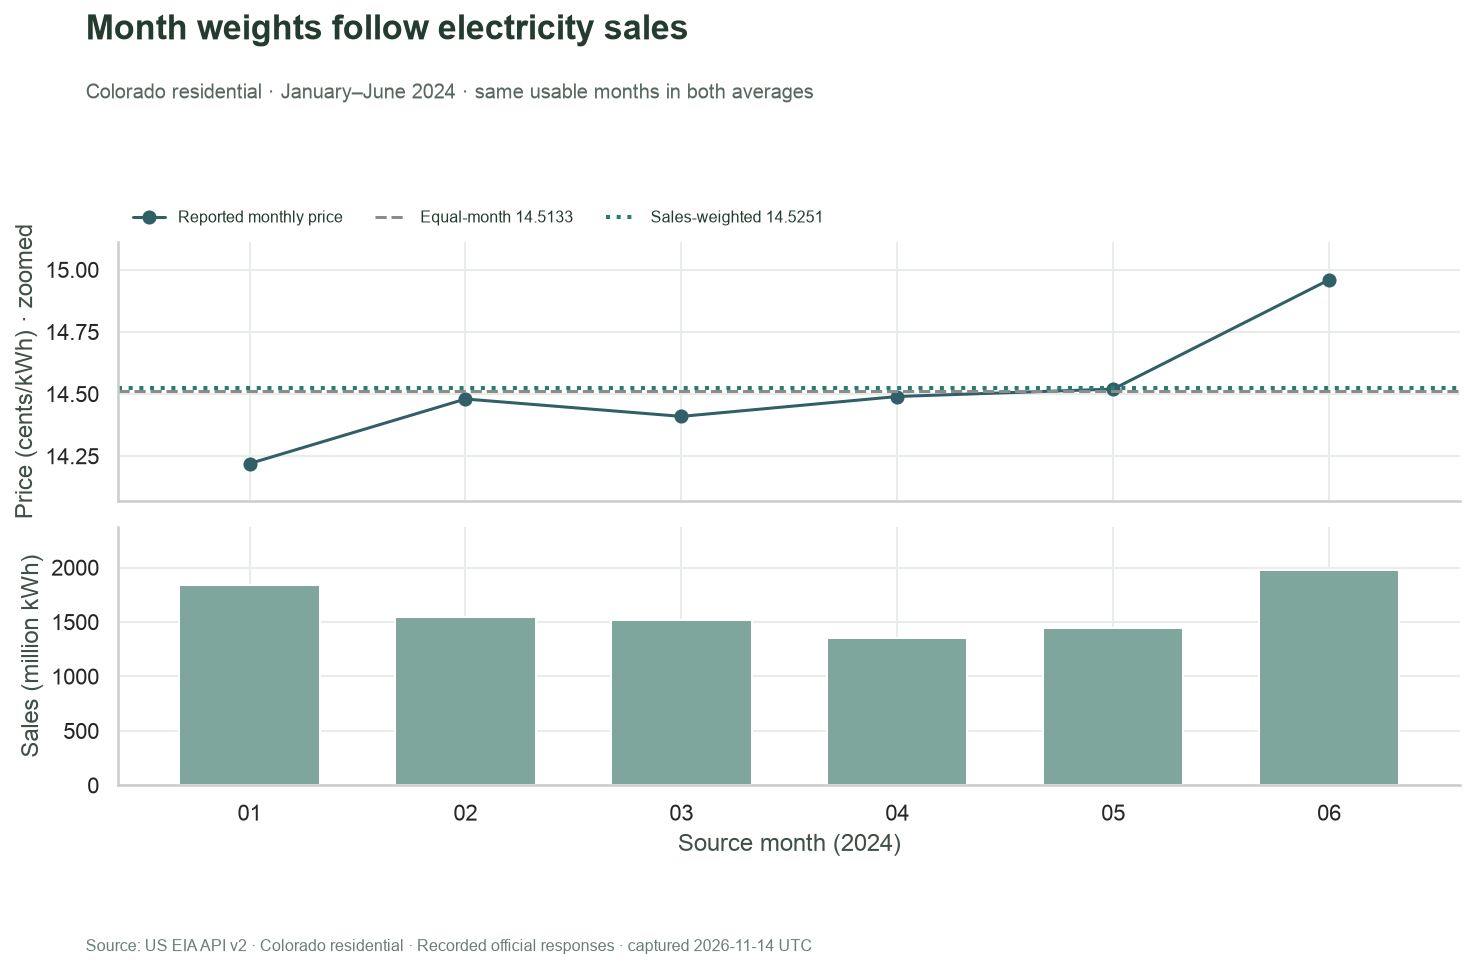

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True)
f = chart_frame
positions = list(range(len(f)))
axes[0].plot(
    positions, f.price_cents_kwh, color="#315F68", marker="o", linewidth=1.5, label="Reported monthly price"
)
axes[0].axhline(
    s.equal_month_price, color="#8B8C8B", linestyle="--", label=f"Equal-month {s.equal_month_price:.4f}"
)
axes[0].axhline(
    s.sales_weighted_price,
    color="#287D70",
    linestyle=":",
    linewidth=2,
    label=f"Sales-weighted {s.sales_weighted_price:.4f}",
)
lo, hi = f.price_cents_kwh.min(), f.price_cents_kwh.max()
margin = max(0.15, (hi - lo) * 0.2)
axes[0].set(ylabel="Price (cents/kWh) · zoomed", ylim=(max(0, lo - margin), hi + margin))
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.18), ncol=3, fontsize=8)
axes[1].bar(positions, f.sales_million_kwh, color="#7FA69D", width=0.65)
axes[1].set(
    ylabel="Sales (million kWh)", xlabel="Source month (2024)", ylim=(0, f.sales_million_kwh.max() * 1.2)
)
axes[1].set_xticks(positions, [period[5:] for period in f.period])
chart(
    fig,
    "Month weights follow electricity sales",
    f"Colorado residential · January–{month_name[END_MONTH]} 2024 · same usable months in both averages",
    source,
)

## Attribute the difference to months

A month's contribution is $(w_i-1/n)(p_i-\bar p)$, in **cents/kWh**. The sum equals
$p_w-\bar p$: weights sum to one, and centered prices sum to zero. A positive bar
means the combination of price deviation and changed weight raises the weighted
mean relative to equal weighting; a negative bar lowers it.

This decomposition describes arithmetic. It does not identify why prices or
sales changed. Bars share a signed axis centered on zero.

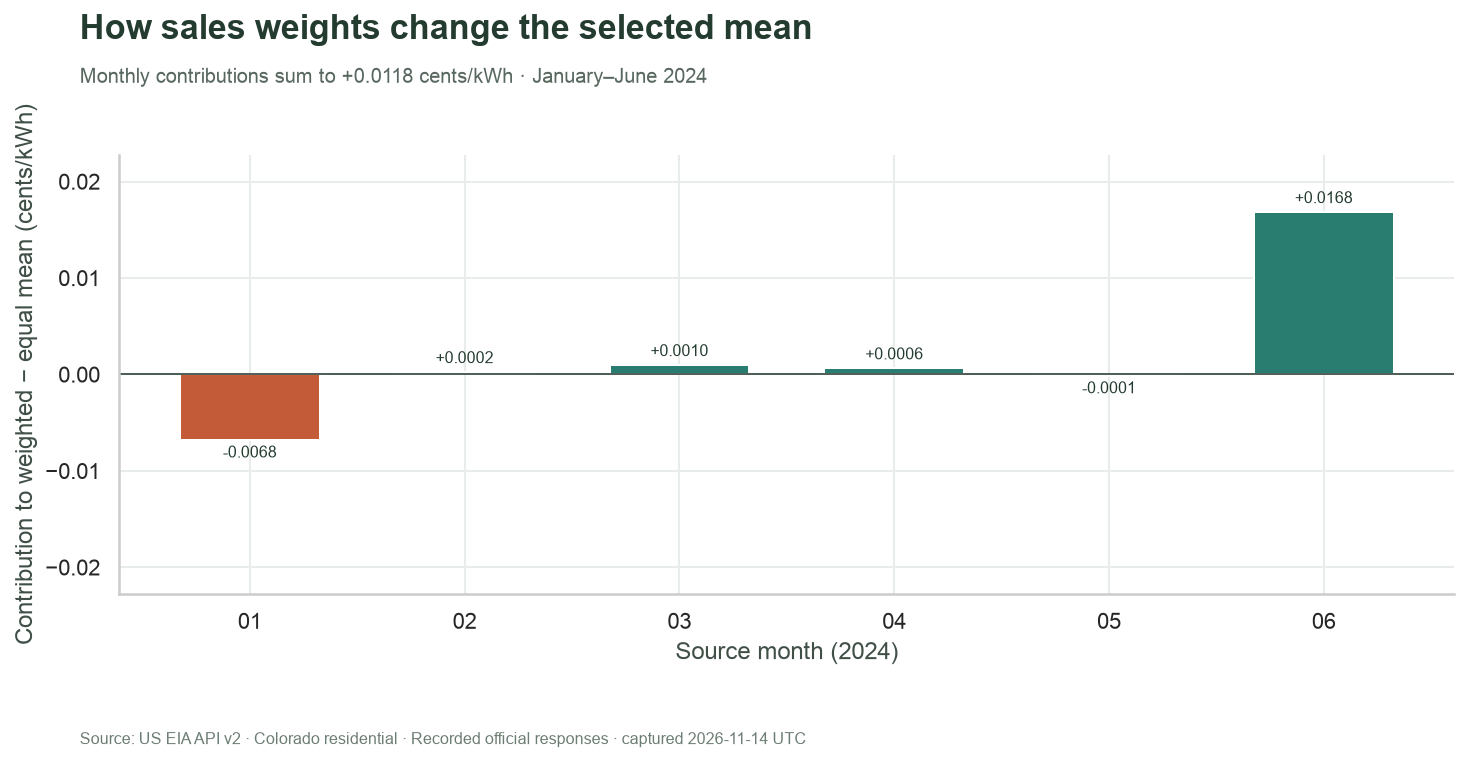

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 5.3))
c = contribution_frame
colors = ["#287D70" if value >= 0 else "#C45B38" for value in c.price_gap_contribution]
ax.bar(c.period.str[5:], c.price_gap_contribution, color=colors, width=0.65)
ax.axhline(0, color="#405047", linewidth=0.9)
span = max(abs(c.price_gap_contribution).max(), 0.001)
for row in c.itertuples():
    ax.text(
        row.period[5:],
        row.price_gap_contribution + (0.035 * span if row.price_gap_contribution >= 0 else -0.035 * span),
        f"{row.price_gap_contribution:+.4f}",
        ha="center",
        va="bottom" if row.price_gap_contribution >= 0 else "top",
        fontsize=8,
    )
ax.set(
    ylim=(-span * 1.35, span * 1.35),
    xlabel="Source month (2024)",
    ylabel="Contribution to weighted − equal mean (cents/kWh)",
)
chart(
    fig,
    "How sales weights change the selected mean",
    f"Monthly contributions sum to {gap:+.4f} cents/kWh · January–{month_name[END_MONTH]} 2024",
    source,
)

## Check identities and the source contract

The checks below validate join keys, units and arithmetic without demanding any
particular direction or size of the price difference. They do not certify EIA
source accuracy or rule out equal-count revisions between independent calls.

In [14]:
%%sql checks <<
SELECT 'Unique price period/state/sector keys' AS check_name,
       count(*)=count(DISTINCT(period,stateid,sectorid)) AS passed FROM prices
UNION ALL SELECT 'Unique sales period/state/sector keys',
       count(*)=count(DISTINCT(period,stateid,sectorid)) FROM sales
UNION ALL SELECT 'Requested source identities and periods',
       bool_and(stateid='CO' AND sectorid='RES' AND frequency='monthly'
         AND period>='2024-01' AND period<='2024-12') FROM (SELECT * FROM prices UNION ALL SELECT * FROM sales)
UNION ALL SELECT 'Measure units match metadata',
       count(*)=2 AND bool_and((measure='price' AND units='cents per kilowatt-hour')
           OR (measure='sales' AND units='million kilowatt hours'))
       FROM measure_metadata WHERE measure IN ('price','sales')
UNION ALL SELECT 'Weights are bounded and sum to one',
       bool_and(sales_weight>=0 AND sales_weight<=1) AND abs(sum(sales_weight)-1)<1e-10 FROM contributions
UNION ALL SELECT 'Weighted mean stays within observed prices',
       sales_weighted_price>=minimum_price-1e-10 AND sales_weighted_price<=maximum_price+1e-10 FROM summary
UNION ALL SELECT 'Contribution identity',
       abs(sum(price_gap_contribution)-(SELECT sales_weighted_price-equal_month_price FROM summary))<1e-10
       FROM contributions
UNION ALL SELECT 'Same paired sample for both means',
       (SELECT paired_months FROM summary)=count(*) AND count(*)<= {{END_MONTH}} FROM paired
UNION ALL SELECT 'Numeric status agrees with NULL behavior',
       bool_and((value_status='numeric')=(value IS NOT NULL)) FROM
       (SELECT * FROM price_source UNION ALL SELECT * FROM sales_source);

In [15]:
display(checks)
assert checks.passed.fillna(False).all(), "A SQL invariant failed; inspect the result table"
if replay:
    assert sorted(replay.requests) == sorted(
        ["metadata"] * 3 + ["price-0", "price-6", "sales-0", "sales-6"]
    ), replay.requests
prose(
    f"**All {len(checks)} SQL checks passed.** "
    + (
        "The recorder served exactly three metadata and four six-row data-page requests. "
        if replay
        else "The official API was queried directly, with no recorded fallback. "
    )
    + "Interpretations refer to the paired-month sample. Reported price rounding, omitted months "
    "and source revisions limit comparisons with a separately published annual figure."
)

,check_name,passed
0,Unique price period/state/sector keys,True
1,Unique sales period/state/sector keys,True
2,Requested source identities and periods,True
3,Measure units match metadata,True
4,Weights are bounded and sum to one,True
5,Weighted mean stays within observed prices,True
6,Contribution identity,True
7,Same paired sample for both means,True
8,Numeric status agrees with NULL behavior,True


**All 9 SQL checks passed.** The recorder served exactly three metadata and four six-row data-page requests. Interpretations refer to the paired-month sample. Reported price rounding, omitted months and source revisions limit comparisons with a separately published annual figure.

## Experiment · extend the comparison to December

Change only **END_MONTH from 6 to 12** in recorded mode. Predict that the usable
month count and total sales can increase; the direction of the price gap is **not**
guaranteed. Compare both means, the paired-month count, and the signed contribution
chart. The fetched full-year source rows remain fixed. Reset to **6** afterward.

```sh
uv run --locked python execute.py --timeout 600 \
  --parameters '{"END_MONTH": 12}' --output-dir artifacts/full-year
```

Live mode is a separate source check, not this controlled experiment. It can fail
on source availability or shared DEMO_KEY quota; neither failure silently changes
the data mode. An operator-owned key belongs in the environment, never in notebook
source or saved output.

In [16]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == [], "No SQL secrets may be introduced"
con.close()
fixture_secret_directory.cleanup()
cleanup(replay, previous_env)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)